# 15 · Bits, compute and quality: where each one pays

A stream can buy quality three ways. The **traditional** way is more bits: the host gives H.264 a
higher bitrate and the client upscales with bicubic, which a GPU's texture sampler does for free.
The other two cost compute: an **upscaler** on the client, and a **hint** - notebook 14's post-filter,
which the host fits and sends - which costs a little traffic, compute on the host, and a little more
on the client. This notebook puts all three in one currency: **bandwidth**.

For every client and bitrate, the question is how many bits the traditional stream would need for
the same quality. That divided by the bits the client's stream really used - video, and the hint's
filters if it has them - is what the client is **worth in bandwidth**: x2 means it looks like a
plain stream at twice the bits; x1 is no better than spending the bits on the video; under x1 is
worse. Where no bitrate reaches a client's quality at all, its worth is unbounded, and the second
currency says how much it adds: **quality at the same bits** - the client's score minus what the
traditional stream scores with the bits the client's stream used. Above 0, the compute bought more
than the same traffic would have. Set against what each client costs to run, the two say where
compute and hints pay most, and where the encoder alone is the better buy.

- **Clips** are notebook 14's: 8 validation sources of each kind - screens, photos, video - whole
  720p clips, streamed the way the host sends today, with the H.264 stream's real coded size.
- **Clients** are the published tile graphs, run as the client runs them: the frame cut into
  320x180 tiles, each with its halo of real neighbours.
- **The traditional stream** is measured further up the bitrate scale (to 3.3 bits per LR pixel),
  so the best client has a plain stream to be matched against. Where quality at a bitrate is
  reached by no bitrate at all - a still screen, which H.264 codes at the same size whatever it is
  given - the clip is counted apart: no amount of bandwidth buys that.

Steps:

1. **Clips** - streamed at every bitrate, and how many bits each really took.
2. **Clients** - every graph, its compute counted from the graph, and the hint's cost.
3. **Measure** - every client on every frame at every bitrate, alone and with the host's
   post-filter refitted every 5th frame.
4. **The traditional stream** - what bits alone buy.
5. **Worth in bandwidth** - by bitrate, for every client.
6. **Bang for the buck** - worth and quality at the same bits, against compute, at the host's
   default bitrate.

Needs: `00_data_preprocess.ipynb`, the downloaded datasets, and the graphs notebooks 4, 10 and 12
published in `dist/upscale/`. Writes nothing.

In [1]:
"""Settings."""

import math

import matplotlib.pyplot as plt
import numpy as np
import onnx
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset

from helpers import degrade, metrics, models, motion, postfilter, sources, training, webexport
from helpers.patches import PatchPairs
from helpers.postfilter import luma
from helpers.training import DATA_DIR, DEVICE

CLIENTS = {   # how a client upscales: a published tile graph, or None for bicubic (the GPU's own sampler)
    "bicubic": None,
    "DirNet B": "upscale_dirnet_fixed_tile320x180.onnx",                 # notebook 12: one 5x5 filter
    "DirNet C": "upscale_dirnet_adaptive_tile320x180.onnx",              # notebook 12: a blend chosen per pixel
    "DirNet D": "upscale_dirnet_full_tile320x180.onnx",                  # notebook 12: C and a learned correction
    "notebook 4": "upscale_strategy_luma_24_2_blocks_tile320x180.onnx",  # luma 24 + 2 residual blocks
    "SDY x2 table": "upscale_lut_sdy_x2_17_tile320x180.onnx",            # notebook 10: look-up tables
}
SOURCES_PER_KIND = 8                                # notebook 14's clips
BITRATES = (0.1, 0.15, 0.25, 0.46, 0.7, 1.0)        # target bits per LR pixel every client is measured at
REFERENCE_BITRATES = (*BITRATES, 1.5, 2.2, 3.3)     # the traditional stream, further up, to match every client
PATH = {"filter": "bicubic", "deblock": False}      # what the host sends today (notebook 8)
REFIT_EVERY = 5                                     # the hint: notebook 14's best schedule

TAPS, LEVELS = 5, 5                 # the post-filter as notebooks 13 and 14 fit it
RIDGE = 1.0                         # pulled toward "no change" with the weight of one pixel
MIN_PIXELS = 2000                   # a class a frame shows less often is left unchanged
COEFFICIENT_BITS, STEP_BITS = 10, 16

CLASSES = postfilter.DIRECTIONS * LEVELS
DEFAULT_BPP = degrade.STREAM_BPP
KINDS = ("screen", "photo", "video")
# the reference palette of the dataviz method, light mode (validate_palette.js: all checks pass)
SURFACE, INK, SECONDARY, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
ALONE, HINTED = "#2a78d6", "#eb6834"
training.seed_everything(0)

## 1. Clips

Notebook 14's clips, streamed at every bitrate of the traditional stream. The coded size is what
counts: x264 holds its bitrate as a ceiling, and a clip that does not need the bits takes fewer.

In [2]:
manifest = training.load_manifest()
SCALE, HALO, CORE = manifest["scale"], manifest["halo"], manifest["patch_lr"]
val_sources = manifest["splits"]["val"]["sources"]


def content(source):
    """What a source shows: a drawn desktop screen, a photo (as a moving clip) or a video."""
    if source["dataset"] == "screens":
        return "screen"
    return "photo" if "motion" in source else "video"


def clip_of(source):
    """A validation source whole, as HR frames (T, h, w, 3) and its frame rate: an image as the
    window that moved over it, a video as every frame it has."""
    path = sources.RAW / source["dataset"] / source["file"]
    if source["dataset"] in sources.SEQUENCES:
        return sources.load_sequence(path)
    shown = motion.Motion(**{**source["motion"], "window": tuple(source["motion"]["window"])})
    return motion.render(sources.load_image(path), shown), manifest["image_clip"]["fps"]


chosen = []
for kind in KINDS:
    of_kind = [source for source in val_sources if content(source) == kind]
    chosen += of_kind[::len(of_kind) // SOURCES_PER_KIND][:SOURCES_PER_KIND]

clips = []   # per source: what it shows, its HR frames and frame rate, and per bitrate its LR frames and coded bits
for source in chosen:
    frames, fps = clip_of(source)
    streams = {}
    for bpp in REFERENCE_BITRATES:
        hr, lr, bits = degrade.degrade(frames, degrade.Degradation(scale=SCALE, bpp=bpp, fps=fps, **PATH), with_bits=True)
        streams[bpp] = (lr, bits)
    clips.append({"kind": content(source), "file": source["file"], "hr": hr, "fps": fps, "streams": streams})

print(f"{'':<8}coded bits per LR pixel, at a target of")
print(f"{'':<8}" + "".join(f"{bpp:>7}" for bpp in REFERENCE_BITRATES))
for kind in KINDS:
    of_kind = [clip for clip in clips if clip["kind"] == kind]
    coded = [np.mean([clip["streams"][bpp][1] / clip["streams"][bpp][0][..., 0].size for clip in of_kind])
             for bpp in REFERENCE_BITRATES]
    print(f"{kind:<8}" + "".join(f"{value:7.3f}" for value in coded))

        coded bits per LR pixel, at a target of
            0.1   0.15   0.25   0.46    0.7    1.0    1.5    2.2    3.3
screen    0.072  0.104  0.158  0.269  0.367  0.474  0.606  0.693  0.810
photo     0.078  0.117  0.195  0.354  0.498  0.632  0.830  1.072  1.420
video     0.086  0.128  0.217  0.395  0.586  0.819  1.143  1.476  1.757


## 2. Clients

Every client's compute is counted from its graph the way notebooks 3 to 12 count it - operations
and memory traffic per LR pixel - except bicubic, which a browser leaves to the GPU's texture
sampler and so costs no shader work at all: it is the chart's baseline, x1 by definition.

**The hint's cost**, worked out rather than counted (its graph does not exist yet):

- **client** - sorting a pixel into its class is four 3-tap Laplacians, their 3x3 averages and a
  few comparisons, about 70 operations an LR pixel; then every HR pixel through a 26-coefficient
  filter, 52 operations, four HR pixels an LR pixel: **about 280 operations an LR pixel**;
- **host** - every 5th frame, the client's model on its own decoded frame, and the normal
  equations: 26 x 27 / 2 + 26 multiply-adds per HR pixel, about 3,000 operations an LR pixel; per
  frame, a fifth of both;
- **traffic** - the filters' own bits, counted per update as notebooks 13 and 14 count them.

In [3]:
POST_FILTER_CLIENT_OPS = 70 + 4 * 2 * (TAPS * TAPS + 1)                       # per LR pixel
POST_FILTER_FIT_OPS = 4 * 2 * ((TAPS * TAPS + 1) * (TAPS * TAPS + 2) // 2 + TAPS * TAPS + 1)

graphs, cost = {}, {"bicubic": {"ops": 0.0, "bytes": 0.0}}
for name, file in CLIENTS.items():
    if file is None:
        continue
    path = webexport.MODELS_DIR / file
    metadata = webexport.read_metadata(onnx.load(str(path)))
    graphs[name] = (webexport.session(path), (int(metadata["step_h"]), int(metadata["step"])), int(metadata["halo"]))
    work = webexport.count_work(path)
    cost[name] = {"ops": work["operations"] / work["input_pixels"], "bytes": work["activation_bytes"] / work["input_pixels"]}


def upscale(name, lr):
    """A client's picture of an LR frame (1, 3, h, w): bicubic, or its graph tile by tile - each
    tile with its halo of real neighbours, the frame's edge repeated outward at the border."""
    if CLIENTS[name] is None:
        return models.bicubic(lr, SCALE)
    runner, (step_h, step_w), halo = graphs[name]
    height, width = lr.shape[2:]
    assert height % step_h == 0 and width % step_w == 0, "the tiles do not divide the frame"
    padded = F.pad(lr, (halo,) * 4, mode="replicate").cpu().numpy()
    out = np.zeros((1, 3, height * SCALE, width * SCALE), np.float32)
    for top in range(0, height, step_h):
        for left in range(0, width, step_w):
            result = webexport.run(runner, padded[:, :, top:top + step_h + 2 * halo, left:left + step_w + 2 * halo])
            out[..., top * SCALE:(top + step_h) * SCALE, left * SCALE:(left + step_w) * SCALE] = \
                result[..., halo * SCALE:(halo + step_h) * SCALE, halo * SCALE:(halo + step_w) * SCALE]
    return torch.from_numpy(out).to(DEVICE)


# the post-filter's classes, from the training set's activity as notebooks 13 and 14 cut it
train_set = PatchPairs(DATA_DIR, "train", manifest, augment=False)
with torch.no_grad():
    sample = torch.cat([luma(lr.to(DEVICE))[..., HALO:HALO + CORE, HALO:HALO + CORE]
                        for lr, _ in DataLoader(Subset(train_set, range(0, len(train_set), 16)), batch_size=256)])
levels = postfilter.activity_levels(sample, LEVELS)
unchanged = torch.zeros(1, CLASSES, TAPS * TAPS + 1, 1, dtype=torch.float64, device=DEVICE)
unchanged[:, :, TAPS * TAPS // 2, 0] = 1   # the filter that leaves a pixel as it is: the client without the hint

print(f"{'':<14}{'ops / LR px':>12}{'bytes / LR px':>15}")
for name, c in cost.items():
    print(f"{name:<14}{c['ops']:12,.0f}{c['bytes']:15,.0f}" + ("   (the GPU's texture sampler)" if name == "bicubic" else ""))
print(f"{'+ the hint':<14}{POST_FILTER_CLIENT_OPS:12,} on the client; on the host, every {REFIT_EVERY}th frame, "
      f"the client's model and {POST_FILTER_FIT_OPS:,} to fit")

               ops / LR px  bytes / LR px
bicubic                  0              0   (the GPU's texture sampler)
DirNet B             1,800            156
DirNet C             8,878          1,896
DirNet D            11,598          2,232
notebook 4          28,120          2,536
SDY x2 table        16,724         32,044
+ the hint             278 on the client; on the host, every 5th frame, the client's model and 3,016 to fit


## 3. Measure

Every client on every frame of every clip, at every bitrate it is measured at (bicubic, the
traditional stream, at the higher ones too). With the hint, the host fits the 25 filters on every
5th frame of the client's own picture against its HR frame, rounds them to what it sends, and the
client uses them on that frame and the four after it. Scores are luma SSIM and PSNR over the whole
720p frame, averaged over the clip.

In [4]:
def to_tensor(images):
    """uint8 (N, h, w, 3) -> float (N, 3, h, w) in [0, 1] on DEVICE."""
    return torch.from_numpy(np.ascontiguousarray(images)).to(DEVICE).permute(0, 3, 1, 2).float() / 255


records = []   # one per clip, bitrate, client and hint
with torch.no_grad():
    for clip in clips:
        frames = len(clip["hr"])
        refits = math.ceil(frames / REFIT_EVERY)
        for bpp, (lr_frames, video_bits) in clip["streams"].items():
            names = list(CLIENTS) if bpp in BITRATES else ["bicubic"]
            pictures, targets, pixel_classes = {name: [] for name in names}, [], []
            fits = {name: postfilter.Fit(refits, CLASSES, 1, TAPS, DEVICE) for name in names}
            for t in range(frames):
                lr, hr = to_tensor(lr_frames[t:t + 1]), to_tensor(clip["hr"][t:t + 1])
                pixel_class = postfilter.upsampled(postfilter.classes(luma(lr), levels), SCALE)
                targets.append(hr)
                pixel_classes.append(pixel_class)
                for name in names:
                    picture = upscale(name, lr)
                    pictures[name].append(picture)
                    if t % REFIT_EVERY == 0 and bpp in BITRATES:
                        fits[name].add(postfilter.windows(luma(picture), TAPS), luma(hr).flatten(2),
                                       pixel_class.flatten(1), torch.full((1,), t // REFIT_EVERY, device=DEVICE))
            for name in names:
                hints = [False] if bpp not in BITRATES else [False, True]
                if True in hints:
                    fit = fits[name]
                    sent = fit.pixels() >= MIN_PIXELS
                    received = torch.where(sent[..., None, None], postfilter.quantise(
                        fit.solve(prior=unchanged, ridge=RIDGE), unchanged, COEFFICIENT_BITS), unchanged).float()
                    hint_bits = int(postfilter.update_bits(sent, 1, TAPS, COEFFICIENT_BITS, STEP_BITS).sum())
                for hint in hints:
                    scores = [metrics.per_image(
                        postfilter.post_filter(pictures[name][t], received, pixel_classes[t],
                                               torch.full((1,), t // REFIT_EVERY, device=DEVICE), TAPS)
                        if hint else pictures[name][t], targets[t]) for t in range(frames)]
                    records.append({"kind": clip["kind"], "file": clip["file"], "bpp": bpp, "client": name,
                                    "hint": hint, "video_bits": video_bits, "hint_bits": hint_bits if hint else 0,
                                    "seconds": frames / clip["fps"], "lr_pixels": lr_frames[..., 0].size,
                                    "ssim": float(torch.cat([s["ssim"] for s in scores]).mean()),
                                    "y": float(torch.cat([s["y"] for s in scores]).mean())})
print(f"{len(records):,} scores of {len(clips)} clips")

1,800 scores of 24 clips


## 4. The traditional stream

What bits alone buy: bicubic on the stream at every bitrate, by kind. The bits are what H.264
really used, per LR pixel.

In [5]:
def pick(**match):
    """The records that match, in clip order."""
    return [r for r in records if all(r[key] == value for key, value in match.items())]


for kind in KINDS:
    print(kind)
    print(f"  {'target':<10}" + "".join(f"{bpp:>8}" for bpp in REFERENCE_BITRATES))
    rows = {bpp: pick(kind=kind, bpp=bpp, client="bicubic", hint=False) for bpp in REFERENCE_BITRATES}
    coded = [np.mean([r["video_bits"] / r["lr_pixels"] for r in rows[bpp]]) for bpp in REFERENCE_BITRATES]
    print(f"  {'coded':<10}" + "".join(f"{value:8.3f}" for value in coded))
    print(f"  {'ssim-y':<10}" + "".join(f"{np.mean([r['ssim'] for r in rows[bpp]]):8.4f}" for bpp in REFERENCE_BITRATES))
    print(f"  {'psnr-y':<10}" + "".join(f"{np.mean([r['y'] for r in rows[bpp]]):8.2f}" for bpp in REFERENCE_BITRATES))

screen
  target         0.1    0.15    0.25    0.46     0.7     1.0     1.5     2.2     3.3
  coded        0.072   0.104   0.158   0.269   0.367   0.474   0.606   0.693   0.810
  ssim-y      0.8826  0.8948  0.9078  0.9195  0.9255  0.9300  0.9331  0.9339  0.9342
  psnr-y       26.07   26.44   26.83   27.11   27.21   27.27   27.29   27.30   27.30
photo
  target         0.1    0.15    0.25    0.46     0.7     1.0     1.5     2.2     3.3
  coded        0.078   0.117   0.195   0.354   0.498   0.632   0.830   1.072   1.420
  ssim-y      0.7076  0.7515  0.7976  0.8350  0.8527  0.8640  0.8730  0.8782  0.8812
  psnr-y       25.94   26.91   27.84   28.54   28.85   29.02   29.15   29.22   29.26
video
  target         0.1    0.15    0.25    0.46     0.7     1.0     1.5     2.2     3.3
  coded        0.086   0.128   0.217   0.395   0.586   0.819   1.143   1.476   1.757
  ssim-y      0.8791  0.9042  0.9314  0.9525  0.9613  0.9661  0.9694  0.9710  0.9717
  psnr-y       32.47   33.82   35.37   36.71  

## 5. Worth in bandwidth

Per clip, the traditional stream is a curve of quality against the bits it really took - kept to
its best so far, since a higher bitrate that scores lower is never the one to pick. A client's
score at a bitrate is found on that curve (linear in log bits between the two bitrates around it),
and the bits there, divided by the bits the client's stream used - its video, and the hint's
filters if it has them - is its worth. Over a kind's clips, the geometric mean; a clip whose score
no bitrate reaches is counted apart (`+n`; `-` when none is reached), and a client scoring under the
traditional stream's lowest bitrate is worth at most what that bitrate gives (`<`). Then quality at the
same bits, which every clip has: the client's score minus the traditional stream's at the bits the
client used, averaged over a kind's clips.

In [6]:
def worth(record, key):
    """The traditional stream's bits for this record's score, over the bits the record used: None if
    no bitrate reaches the score, and whether it is only an upper bound (under the lowest bitrate)."""
    plain = sorted((r["video_bits"], r[key]) for r in pick(file=record["file"], client="bicubic", hint=False))
    bits = np.array([b for b, _ in plain], float)
    curve = np.maximum.accumulate([q for _, q in plain])
    quality, used = record[key], record["video_bits"] + record["hint_bits"]
    if quality > curve[-1]:
        return None, False
    if quality <= curve[0]:
        return bits[0] / used, True
    i = int(np.searchsorted(curve, quality))   # the first bitrate that reaches it
    share = (quality - curve[i - 1]) / (curve[i] - curve[i - 1])
    return math.exp(math.log(bits[i - 1]) + share * math.log(bits[i] / bits[i - 1])) / used, False


def at_same_bits(record, key):
    """The record's score minus the traditional stream's with the bits the record used (its curve,
    kept to its best so far; past its highest bitrate, that best)."""
    plain = sorted((r["video_bits"], r[key]) for r in pick(file=record["file"], client="bicubic", hint=False))
    bits = np.array([b for b, _ in plain], float)
    curve = np.maximum.accumulate([q for _, q in plain])
    used = record["video_bits"] + record["hint_bits"]
    return record[key] - np.interp(math.log(used), np.log(bits), curve)


def summary(kind, client, hint, bpp, key):
    """The geometric mean of `worth` over a kind's clips, how many no bitrate reaches, and whether any is a bound."""
    found = [worth(r, key) for r in pick(kind=kind, client=client, hint=hint, bpp=bpp)]
    reached = [value for value, _ in found if value is not None]
    mean = math.exp(np.mean(np.log(reached))) if reached else float("nan")
    return mean, len(found) - len(reached), any(bound for value, bound in found if value is not None)


def label(client, hint):
    return client + (" + hint" if hint else "")


def cell(kind, client, hint, bpp, key):
    mean, unreached, bound = summary(kind, client, hint, bpp, key)
    text = "-" if math.isnan(mean) else ("<" if bound else "") + f"x{mean:.2f}"
    return f"{text + (f' +{unreached}' if unreached else ''):>12}"


def gain(kind, client, hint, bpp, key):
    """`at_same_bits`, averaged over a kind's clips."""
    return float(np.mean([at_same_bits(r, key) for r in pick(kind=kind, client=client, hint=hint, bpp=bpp)]))


for key, metric in (("ssim", "SSIM-Y"), ("y", "PSNR-Y")):
    print(f"worth in bandwidth, for the same {metric}, at a target of")
    print(f"{'':<26}" + "".join(f"{bpp:>12}" for bpp in BITRATES))
    for kind in KINDS:
        print(kind)
        for client in CLIENTS:
            for hint in (False, True):
                if client == "bicubic" and not hint:
                    continue
                print(f"  {label(client, hint):<24}" + "".join(cell(kind, client, hint, bpp, key) for bpp in BITRATES))
    print()

print("quality at the same bits: SSIM-Y / dB luma over the traditional stream with the bits the client's stream used")
print(f"{'':<26}" + "".join(f"{bpp:>16}" for bpp in BITRATES))
for kind in KINDS:
    print(kind)
    for client in CLIENTS:
        for hint in (False, True):
            if client == "bicubic" and not hint:
                continue
            print(f"  {label(client, hint):<24}" + "".join(
                f"{gain(kind, client, hint, bpp, 'ssim'):+.4f}/{gain(kind, client, hint, bpp, 'y'):+.2f}".rjust(16)
                for bpp in BITRATES))

worth in bandwidth, for the same SSIM-Y, at a target of
                                   0.1        0.15        0.25        0.46         0.7         1.0
screen
  bicubic + hint             <x1.42 +2    x1.72 +3    x1.55 +5    x1.28 +7    x1.34 +7    x2.07 +7
  DirNet B                   <x1.01 +1    x1.03 +3    x1.04 +4    x1.11 +6    x0.89 +7    x0.96 +7
  DirNet B + hint            <x1.36 +2    x1.60 +3    x1.52 +5    x1.27 +7    x1.34 +7    x2.19 +7
  DirNet C                    x1.36 +3    x1.72 +4    x1.35 +6    x1.55 +7    x2.06 +7        - +8
  DirNet C + hint             x1.70 +4    x2.26 +4    x1.96 +6    x2.10 +7        - +8        - +8
  DirNet D                    x1.57 +3    x2.05 +4    x1.52 +6    x1.72 +7    x3.19 +7        - +8
  DirNet D + hint             x1.75 +4    x2.07 +5    x2.09 +6    x2.23 +7        - +8        - +8
  notebook 4                  x1.77 +3    x1.76 +4    x1.50 +6    x1.47 +7    x1.80 +7        - +8
  notebook 4 + hint           x1.65 +4    x2.2

## 6. Bang for the buck

At the host's default bitrate: what each client costs - on the client, on the host, in traffic -
against what it is worth in bandwidth and what it adds at the same bits, both for SSIM-Y. The chart
is the second, by kind: up is more quality than the traditional stream with the same traffic, right
is more compute on the client.

                         client ops  host ops  traffic  screen: worth, same bits   photo: worth, same bits   video: worth, same bits
bicubic + hint                  278       603     1.7%         x1.28 +7  +0.0112            x1.26  +0.0116         x1.63 +1  +0.0088
DirNet B                      1,800         0     0.0%         x1.11 +6  +0.0044            x1.07  +0.0028         x0.83 +1  -0.0022
DirNet B + hint               2,078       963     1.7%         x1.27 +7  +0.0112            x1.26  +0.0116         x1.64 +1  +0.0088
DirNet C                      8,878         0     0.0%         x1.55 +7  +0.0357         x1.16 +1  +0.0128         x1.29 +2  +0.0086
DirNet C + hint               9,156     2,379     1.7%         x2.10 +7  +0.0405         x1.33 +2  +0.0179         x1.83 +2  +0.0146
DirNet D                     11,598         0     0.0%         x1.72 +7  +0.0365         x1.20 +1  +0.0147         x1.53 +2  +0.0108
DirNet D + hint              11,876     2,923     1.7%         x2.23 

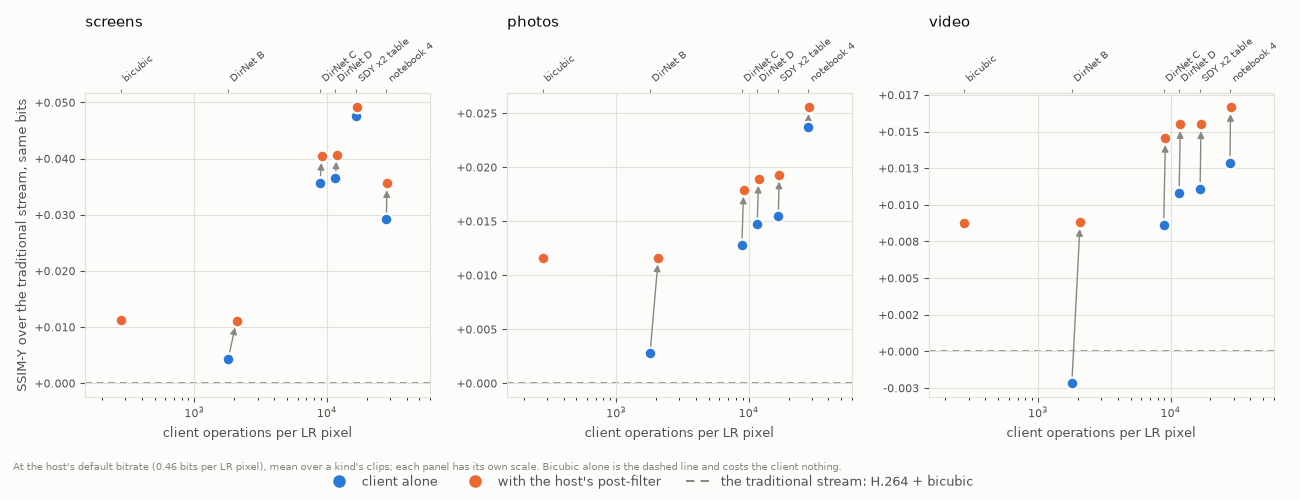

In [7]:
print(f"{'':<24}{'client ops':>11}{'host ops':>10}{'traffic':>9}" + "".join(f"{kind + ': worth, same bits':>26}" for kind in KINDS))
for client in CLIENTS:
    for hint in (False, True):
        if client == "bicubic" and not hint:
            continue
        ops = cost[client]["ops"] + (POST_FILTER_CLIENT_OPS if hint else 0)
        host = (cost[client]["ops"] + POST_FILTER_FIT_OPS) / REFIT_EVERY if hint else 0
        rows = pick(client=client, hint=hint, bpp=DEFAULT_BPP)
        traffic = np.mean([r["hint_bits"] / r["video_bits"] for r in rows])
        cells = []
        for kind in KINDS:
            mean, unreached, _ = summary(kind, client, hint, DEFAULT_BPP, "ssim")
            text = "-" if math.isnan(mean) else f"x{mean:.2f}"
            cells.append(f"{text}{f' +{unreached}' if unreached else ''}  {gain(kind, client, hint, DEFAULT_BPP, 'ssim'):+.4f}")
        print(f"{label(client, hint):<24}{ops:11,.0f}{host:10,.0f}{traffic:9.1%}" + "".join(f"{c:>26}" for c in cells))
print("\nops per LR pixel; host: a frame's share of every 5th frame's model and fit; traffic: the hint's bits over the video's;"
      "\nworth: the traditional stream's bits for the same SSIM-Y over the bits used (+n: clips no bitrate reaches);"
      "\nsame bits: SSIM-Y over the traditional stream with the bits used")

fig, axes = plt.subplots(1, len(KINDS), figsize=(13, 5), facecolor=SURFACE)
for ax, kind in zip(axes, KINDS):
    ax.set_facecolor(SURFACE)
    ax.axhline(0.0, color=MUTED, linewidth=1.2, linestyle=(0, (4, 3)), zorder=1)
    for client in CLIENTS:
        x = cost[client]["ops"]
        hinted = gain(kind, client, True, DEFAULT_BPP, "ssim")
        if client != "bicubic":   # bicubic alone is the dashed line itself
            alone = gain(kind, client, False, DEFAULT_BPP, "ssim")
            ax.annotate("", xy=(x + POST_FILTER_CLIENT_OPS, hinted), xytext=(x, alone), zorder=2,
                        arrowprops={"arrowstyle": "-|>", "color": MUTED, "linewidth": 1.0, "shrinkA": 5, "shrinkB": 5})
            ax.scatter([x], [alone], s=70, color=ALONE, edgecolors=SURFACE, linewidths=1.5, zorder=3)
        ax.scatter([x + POST_FILTER_CLIENT_OPS], [hinted], s=70, color=HINTED, edgecolors=SURFACE, linewidths=1.5, zorder=3)
    ax.set_xscale("log")
    ax.set_xlim(150, 6e4)
    names = ax.secondary_xaxis("top")   # the clients, named once along the top, where they sit
    names.set_xticks([cost[client]["ops"] or POST_FILTER_CLIENT_OPS for client in CLIENTS], labels=list(CLIENTS))
    names.tick_params(axis="x", labelrotation=40, labelsize=7.5, labelcolor=SECONDARY, color=MUTED, length=3)
    names.minorticks_off()
    for text in names.get_xticklabels():
        text.set_horizontalalignment("left")
    names.spines["top"].set_color(GRID)
    ax.set_title(f"{kind}s" if kind != "video" else "video", color=INK, fontsize=11, loc="left", pad=48)
    ax.set_xlabel("client operations per LR pixel", color=SECONDARY, fontsize=9)
    ax.grid(color=GRID, linewidth=0.8)
    ax.tick_params(colors=SECONDARY, labelsize=8)
    for spine in ax.spines.values():
        spine.set_color(GRID)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:+.3f}"))
axes[0].set_ylabel("SSIM-Y over the traditional stream, same bits", color=SECONDARY, fontsize=9)
handles = [plt.Line2D([], [], marker="o", linestyle="", markersize=8, color=ALONE, label="client alone"),
           plt.Line2D([], [], marker="o", linestyle="", markersize=8, color=HINTED, label="with the host's post-filter"),
           plt.Line2D([], [], color=MUTED, linestyle=(0, (4, 3)), label="the traditional stream: H.264 + bicubic")]
fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0.0), ncol=3, frameon=False, fontsize=9,
           labelcolor=SECONDARY)
fig.text(0.01, 0.06, f"At the host's default bitrate ({DEFAULT_BPP} bits per LR pixel), mean over a kind's clips; each panel "
         "has its own scale. Bicubic alone is the dashed line and costs the client nothing.", fontsize=7.5, color=MUTED)
fig.tight_layout(rect=(0, 0.09, 1, 1))
plt.show()